# K-Means Clustering Task
This notebook loads `Country-data.csv`, explores relationships with `gdpp`, normalises the data, finds the optimal number of clusters, fits a K-Means model, reports the silhouette score, visualises clusters, and provides guidance for labeling country groups.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

%matplotlib inline


In [2]:

df = pd.read_csv('Country-data.csv')
print(df.head())
print("\nColumns:")
print(df.columns.tolist())


               country  child_mort  exports  health  imports  income  \
0          Afghanistan        90.2     10.0    7.58     44.9    1610   
1              Albania        16.6     28.0    6.55     48.6    9930   
2              Algeria        27.3     38.4    4.17     31.4   12900   
3               Angola       119.0     62.3    2.85     42.9    5900   
4  Antigua and Barbuda        10.3     45.5    6.03     58.9   19100   

   inflation  life_expec  total_fer   gdpp  
0       9.44        56.2       5.82    553  
1       4.49        76.3       1.65   4090  
2      16.10        76.5       2.89   4460  
3      22.40        60.1       6.16   3530  
4       1.44        76.8       2.13  12200  

Columns:
['country', 'child_mort', 'exports', 'health', 'imports', 'income', 'inflation', 'life_expec', 'total_fer', 'gdpp']


In [3]:

# Drop non-numeric columns
numeric_df = df.select_dtypes(include='number')

print("Numeric columns:")
print(numeric_df.columns.tolist())

numeric_df.head()


Numeric columns:
['child_mort', 'exports', 'health', 'imports', 'income', 'inflation', 'life_expec', 'total_fer', 'gdpp']


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


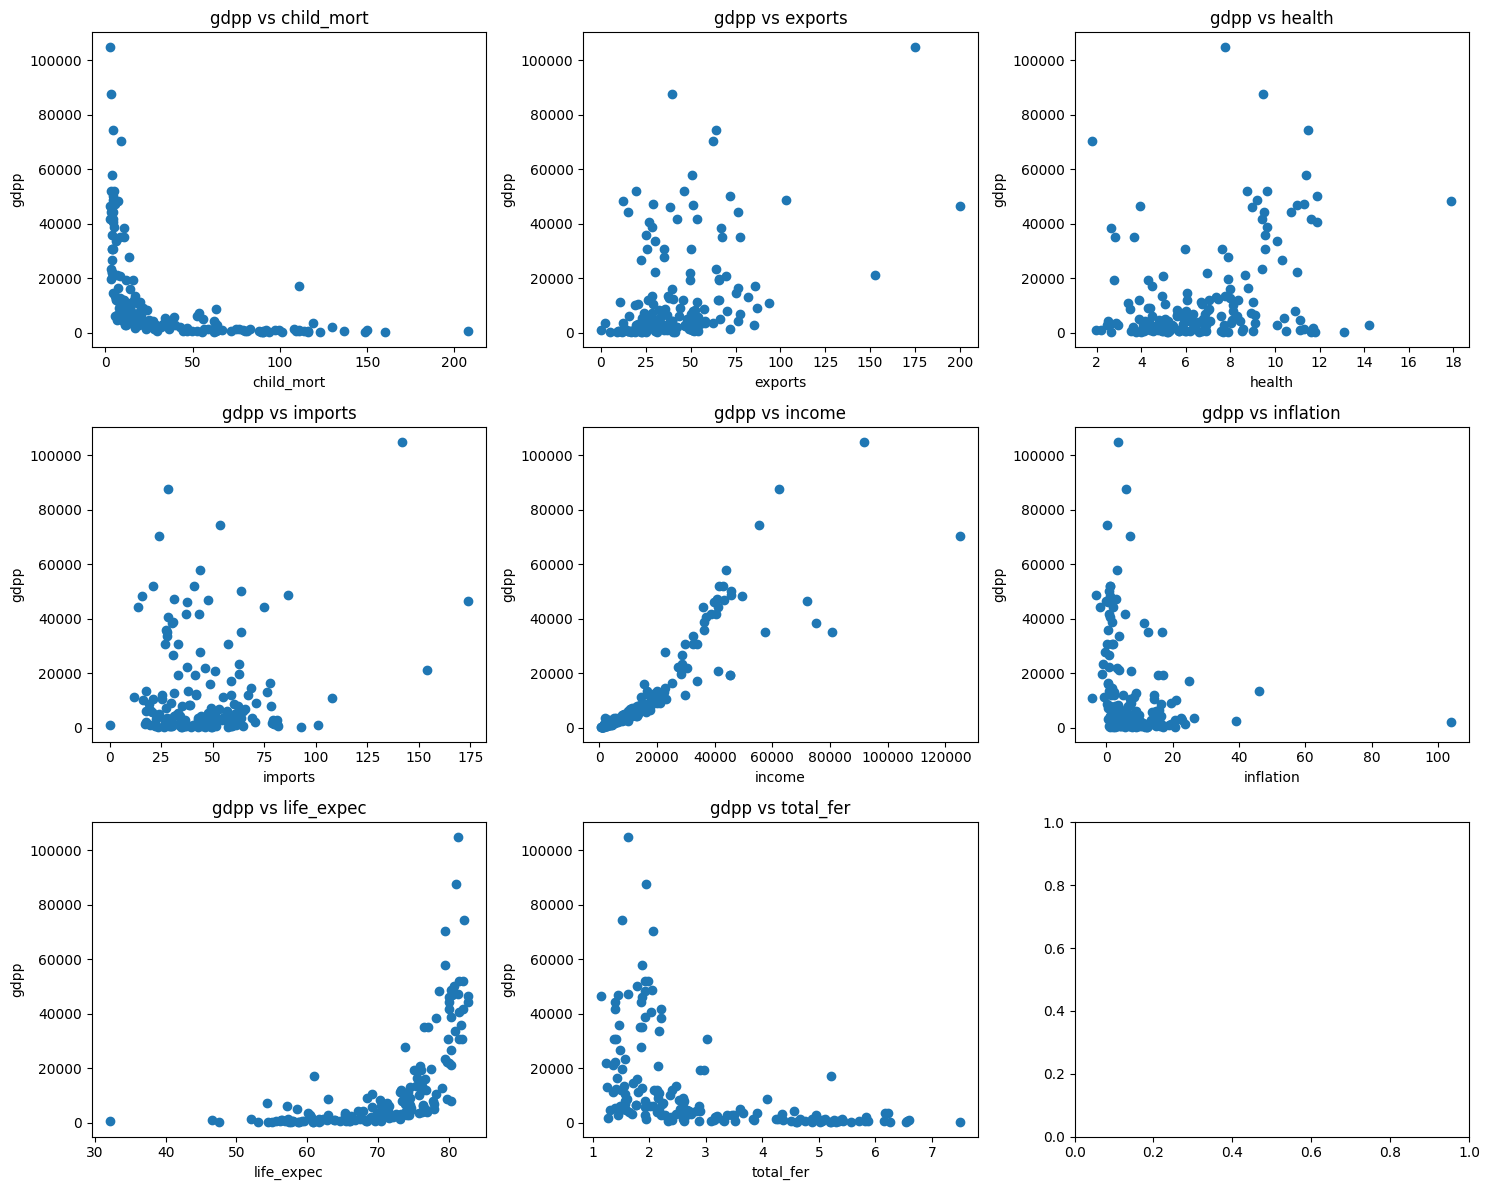

Inspect the plots and identify which variable appears to separate clusters most clearly.


In [4]:

# Nine scatter plots against gdpp
cols = [c for c in numeric_df.columns if c != 'gdpp'][:9]

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for ax, col in zip(axes, cols):
    ax.scatter(numeric_df[col], numeric_df['gdpp'])
    ax.set_xlabel(col)
    ax.set_ylabel('gdpp')
    ax.set_title(f'gdpp vs {col}')

plt.tight_layout()
plt.show()

print("Inspect the plots and identify which variable appears to separate clusters most clearly.")


In [5]:

# Normalise using MinMaxScaler
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(numeric_df)

scaled_df = pd.DataFrame(scaled_data, columns=numeric_df.columns)
scaled_df.head()


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,0.426485,0.049482,0.358608,0.257765,0.008047,0.126144,0.475345,0.736593,0.003073
1,0.068160,0.139531,0.294593,0.279037,0.074933,0.080399,0.871795,0.078864,0.036833
2,0.120253,0.191559,0.146675,0.180149,0.098809,0.187691,0.875740,0.274448,0.040365
3,0.566699,0.311125,0.064636,0.246266,0.042535,0.245911,0.552268,0.790221,0.031488
4,0.037488,0.227079,0.262275,0.338255,0.148652,0.052213,0.881657,0.154574,0.114242


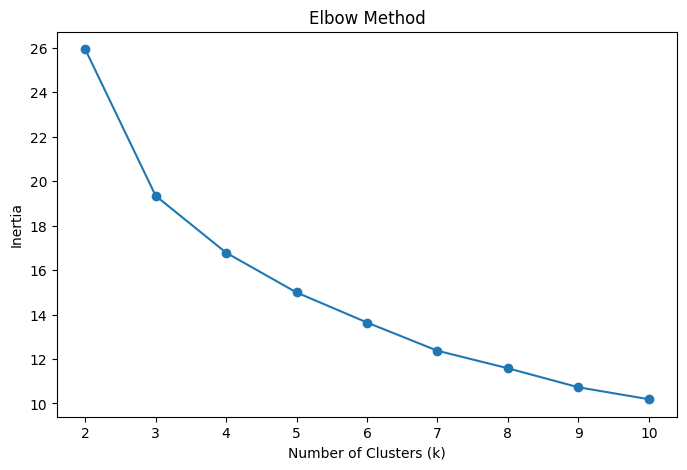

In [6]:

# Elbow method
inertias = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(scaled_df)
    inertias.append(model.inertia_)

plt.figure(figsize=(8,5))
plt.plot(list(k_values), inertias, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()


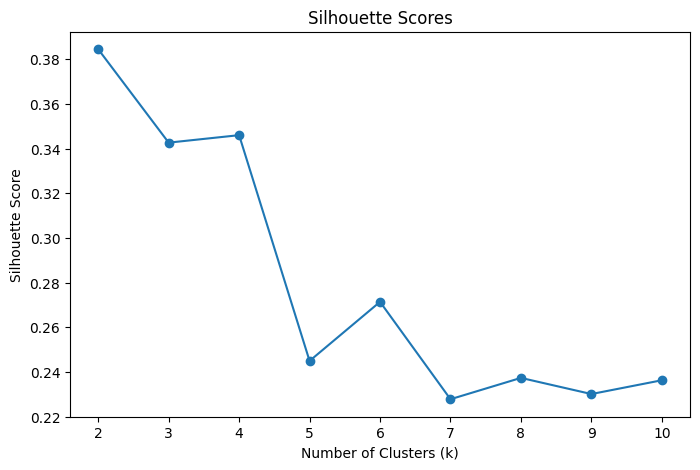

Best k based on silhouette score: 2


In [7]:

# Silhouette scores
sil_scores = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(scaled_df)
    sil_scores.append(silhouette_score(scaled_df, labels))

plt.figure(figsize=(8,5))
plt.plot(range(2,11), sil_scores, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Scores')
plt.show()

best_k = range(2,11)[np.argmax(sil_scores)]
print("Best k based on silhouette score:", best_k)


In [8]:

# Fit final model
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
clusters = kmeans.fit_predict(scaled_df)

numeric_df['Cluster'] = clusters

final_silhouette = silhouette_score(scaled_df, clusters)
print("Final silhouette score:", final_silhouette)

numeric_df[['Cluster']].head()


Final silhouette score: 0.384471920619431


,Cluster
0,1
1,0
2,0
3,1
4,0


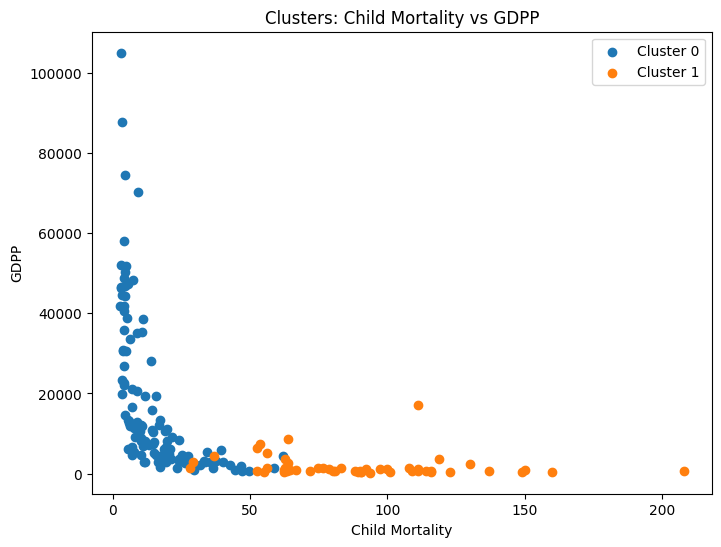

In [9]:

# Child mortality vs GDPP
plt.figure(figsize=(8,6))
for c in sorted(numeric_df['Cluster'].unique()):
    subset = numeric_df[numeric_df['Cluster'] == c]
    plt.scatter(subset['child_mort'], subset['gdpp'], label=f'Cluster {c}')

plt.xlabel('Child Mortality')
plt.ylabel('GDPP')
plt.title('Clusters: Child Mortality vs GDPP')
plt.legend()
plt.show()


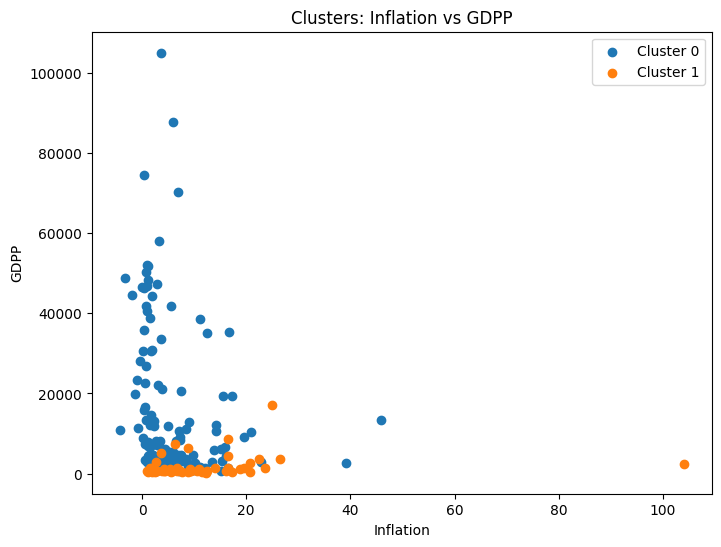

In [10]:

# Inflation vs GDPP
plt.figure(figsize=(8,6))
for c in sorted(numeric_df['Cluster'].unique()):
    subset = numeric_df[numeric_df['Cluster'] == c]
    plt.scatter(subset['inflation'], subset['gdpp'], label=f'Cluster {c}')

plt.xlabel('Inflation')
plt.ylabel('GDPP')
plt.title('Clusters: Inflation vs GDPP')
plt.legend()
plt.show()


In [11]:

# Cluster summary for assigning labels
cluster_summary = numeric_df.groupby('Cluster')[['child_mort', 'gdpp', 'inflation']].mean()
cluster_summary.sort_values('gdpp')


,child_mort,gdpp,inflation
Cluster,,,
1,89.084314,1888.980392,11.645000
0,15.929310,17833.413793,6.083371



### Interpreting and Labeling Clusters

Use the cluster summary table above.

Suggested approach:

- High child mortality + low GDPP -> Least Developed / Low Income
- Moderate child mortality + moderate GDPP -> Developing / Lower-Middle Income
- Low child mortality + high GDPP -> Developed / High Income
- If four clusters exist, add an Upper-Middle Income category.

Justify labels by comparing:
1. Average GDPP in each cluster.
2. Average child mortality.
3. Average inflation.

Clusters with stronger economies generally have higher GDPP and lower child mortality.
